In [1]:
from model.trans_model2 import Trans_volleyball
import torch
import torch.optim as optim
import torch.distributed as dist
import torch.nn.functional as F
import numpy as np
from dataload.dataset import return_dataloader
from utils import print_log

In [2]:
from configs import get_config
my_config = "volleyball_trans_post_infer"
cfg = get_config(my_config)

In [52]:
gcnnet_list = {
        # 'SAM_NBA': SAM_NBA,
        # 'volleyball': GCNnet_volleyball,
        # 'collective': GCNnet_collective,
        # 'dynamic_volleyball': Dynamic_volleyball,
        # 'dynamic_tce_volleyball': Dynamic_TCE_volleyball,
        # 'pctdm_volleyball': PCTDM_volleyball,
        # 'higcin_volleyball': HiGCIN_volleyball,
        # 'at_volleyball': AT_volleyball,
        # 'arg_volleyball': ARG_volleyball,
        # 'sacrf_biute_volleyball': SACRF_BiUTE_volleyball,
        # 'dynamic_collective': Dynamic_collective,
        'trans_volleyball': Trans_volleyball
}

def get_feats(cfg):
    cfg.init_config(0)
    # log_path = os.path.join(cfg.result_path, 'runs')
    # tb_logger = SummaryWriter(log_path)
    if cfg.training_stage == 1:
        Basenet = basenet_list[cfg.dataset_name]
        model = Basenet(cfg)
    elif cfg.training_stage == 2:
        GCNnet = gcnnet_list[cfg.inference_module_name]
        model = GCNnet(cfg)
        # Load backbone
        if cfg.load_backbone_stage2:
            # 载入一阶段的模型
            model.loadmodel(cfg.stage1_model_path)
            if cfg.load_posemodel:
                model.loadpose(cfg.pose_model_path)
        elif cfg.load_stage2model:
            state = torch.load(cfg.stage2model)
            model.load_state_dict(state['state_dict'])
            print_log(cfg.log_path, 'Loading stage2 model: ' + cfg.stage2model)
        else:
            print_log(cfg.log_path, 'Not loading stage1 or stage2 model.')
    else:
        assert False
    # build dataloader
    training_loader, validation_loader = return_dataloader(cfg)
    model.to(device=0)
    model.eval()
    all_feats = []
    all_labels = []
    with torch.no_grad():
        for i, batch_data_test in enumerate(validation_loader):
            # if i>30: break
#             data_time.update(time.time() - batch_start_time)

            # prepare batch data
            batch_data_test = [b.to(device=0) for b in batch_data_test]
            batch_size = batch_data_test[0].shape[0]
            num_frames = batch_data_test[0].shape[1]
            actions_in = batch_data_test[2]
            activities_in = batch_data_test[3]
            batch_video = batch_data_test[5];
            batch_clip = batch_data_test[6];
            # 第一个帧的所有batch的action id 向量
            actions_in = actions_in[:, 0, :].reshape((batch_size * cfg.num_boxes))
            activities_in = activities_in[:, 0]#.reshape((batch_size,))

            # forward
            # 得到个体分数和群体行为分数
            ret = model(batch_data_test[0], batch_data_test[1], batch_data_test[4])
            tgt = ret['tgt'] # B,T,F
            # print(tgt.shape)
            feats = tgt.mean(dim = 0)
            # print(feats.shape)
            all_feats.append(feats.cpu().detach().numpy())
            all_labels.append(activities_in.cpu().detach().numpy())
    all_labels = np.stack(all_labels,axis=0)
    all_features = np.stack(all_feats,axis=0)
    print(all_features.shape)
    print(all_labels.shape)
    return all_features,all_labels

In [3]:
import os
import torch.distributed as dist
os.environ['CUDA_VISIBLE_DEVICES'] = "4"
def ddp_setup(rank, world_size):
    os.environ["MASTER_ADDR"] = "localhost"
    os.environ["MASTER_PORT"] = "12355"
    dist.init_process_group(backend='nccl', rank=rank, world_size=world_size)

In [4]:
world_si = torch.cuda.device_count()
world_si

1

In [5]:
ddp_setup(0, world_si)

In [6]:
result,labels = get_feats(cfg)

NameError: name 'get_feats' is not defined

In [49]:
labels

array([[0],
       [4],
       [4],
       [2],
       [5],
       [4],
       [2],
       [6],
       [0],
       [2],
       [7],
       [0],
       [1],
       [1],
       [6],
       [2],
       [6],
       [1],
       [1],
       [2],
       [4],
       [1],
       [4],
       [2],
       [5],
       [1],
       [6],
       [1],
       [5],
       [2],
       [1]])

In [55]:
result.shape

(1337, 512)

In [202]:
from sklearn.manifold import TSNE
X_embedded = TSNE(n_components=2, perplexity=20,learning_rate=10,early_exaggeration=10).fit_transform(result)
print(X_embedded.shape)

(1337, 2)


In [115]:
lb = np.array(['r_set', 'r_spike', 'r-pass', 'r_winpoint',
              'l_set', 'l-spike', 'l-pass', 'l_winpoint'])

In [94]:
    lb[1]

'r_spike'

In [118]:
lb[labels].reshape(-1)

array(['r_set', 'l_set', 'l_set', ..., 'l-pass', 'l_winpoint',
       'r_winpoint'], dtype='<U10')

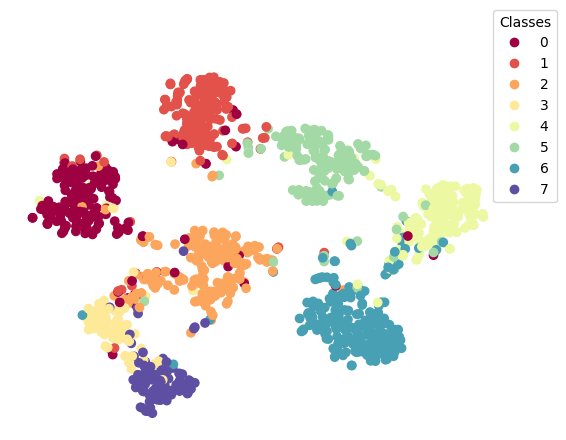

In [208]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
scatter =  ax.scatter(X_embedded[:, 0], X_embedded[:, 1], c=labels,cmap=plt.cm.Spectral)
kw = dict(fmt="$ {lb[x]:.}")
legend1 = fig.legend(*scatter.legend_elements(), title="Classes",bbox_to_anchor=(0.52, 0.1, 0.47, 0.9))
# fig.legend()
ax.axis('off')
# ax.add_artist(legend1)
plt.savefig('./tsne.jpg')

In [6]:
gcnnet_list = {
        # 'SAM_NBA': SAM_NBA,
        # 'volleyball': GCNnet_volleyball,
        # 'collective': GCNnet_collective,
        # 'dynamic_volleyball': Dynamic_volleyball,
        # 'dynamic_tce_volleyball': Dynamic_TCE_volleyball,
        # 'pctdm_volleyball': PCTDM_volleyball,
        # 'higcin_volleyball': HiGCIN_volleyball,
        # 'at_volleyball': AT_volleyball,
        # 'arg_volleyball': ARG_volleyball,
        # 'sacrf_biute_volleyball': SACRF_BiUTE_volleyball,
        # 'dynamic_collective': Dynamic_collective,
        'trans_volleyball': Trans_volleyball
}

def get_attents(cfg):
    cfg.init_config(0)
    # log_path = os.path.join(cfg.result_path, 'runs')
    # tb_logger = SummaryWriter(log_path)
    if cfg.training_stage == 1:
        Basenet = basenet_list[cfg.dataset_name]
        model = Basenet(cfg)
    elif cfg.training_stage == 2:
        GCNnet = gcnnet_list[cfg.inference_module_name]
        model = GCNnet(cfg)
        # Load backbone
        if cfg.load_backbone_stage2:
            # 载入一阶段的模型
            model.loadmodel(cfg.stage1_model_path)
            if cfg.load_posemodel:
                model.loadpose(cfg.pose_model_path)
        elif cfg.load_stage2model:
            state = torch.load(cfg.stage2model)
            model.load_state_dict(state['state_dict'])
            print_log(cfg.log_path, 'Loading stage2 model: ' + cfg.stage2model)
        else:
            print_log(cfg.log_path, 'Not loading stage1 or stage2 model.')
    else:
        assert False
    # build dataloader
    training_loader, validation_loader = return_dataloader(cfg)
    model.to(device=0)
    model.eval()
    results = []
    with torch.no_grad():
        for i, batch_data_test in enumerate(validation_loader):
            if i>30: break
#             data_time.update(time.time() - batch_start_time)

            # prepare batch data
            batch_data_test = [b.to(device=0) for b in batch_data_test]
            batch_size = batch_data_test[0].shape[0]
            num_frames = batch_data_test[0].shape[1]
            actions_in = batch_data_test[2]
            activities_in = batch_data_test[3]
            batch_video = batch_data_test[5];
            batch_clip = batch_data_test[6];
            # 第一个帧的所有batch的action id 向量
            actions_in = actions_in[:, 0, :].reshape((batch_size * cfg.num_boxes))
            activities_in = activities_in[:, 0]#.reshape((batch_size,))

            # forward
            # 得到个体分数和群体行为分数
            ret = model(batch_data_test[0], batch_data_test[1], batch_data_test[4])
            gas,gat,vis = ret['graph']
            results.append((gas,gat,vis,batch_data_test[0],batch_data_test[1],activities_in))
    return results

In [7]:
ret = get_attents(cfg)

/data1/anaconda3/envs/vad/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/data1/anaconda3/envs/vad/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


NFB:512
D:512
J*NFB:8704
T*self.joint_init_fea_dim:30
Loading stage2 model: result/[Trans Volleyball_stage2_KST_base_stage2]<2024-03-14_19-27-20>/stage2_epoch18_91.25%.pth


In [190]:
gas,gat,vis,imgs,boxes,label = ret[28]
images = imgs[0]
images.shape

torch.Size([10, 3, 720, 1280])

In [37]:
gat

tensor([[[0.1000],
         [0.1000],
         [0.1000],
         [0.1000],
         [0.1000],
         [0.1000],
         [0.1000],
         [0.1000],
         [0.1000],
         [0.1000]]], device='cuda:0')

In [191]:
lb = np.array(['r_set', 'r_spike', 'r-pass', 'r_winpoint',
              'l_set', 'l-spike', 'l-pass', 'l_winpoint'])
lb[label]

'l-spike'

In [192]:
(boxes[:,:,:,0] + boxes[:,:,:,2])

tensor([[[23.2125, 29.0813, 30.6566, 33.6006, 37.2380, 33.1105, 41.1320,
          41.1763, 44.3465, 55.4651, 60.2633, 59.6880],
         [22.8699, 29.1051, 30.6593, 33.3351, 36.9875, 33.0235, 41.0449,
          41.0115, 44.3237, 55.3094, 59.8801, 59.4906],
         [22.3897, 29.1528, 30.4459, 33.0256, 36.6826, 32.9377, 40.8816,
          40.7231, 44.4776, 55.1851, 59.5090, 59.3065],
         [22.0523, 28.9219, 30.1450, 32.7568, 36.3627, 32.8441, 40.7181,
          40.4397, 44.4345, 54.9697, 59.1321, 59.0529],
         [21.5679, 28.7588, 29.8992, 32.5148, 36.1202, 32.6485, 40.5588,
          40.1875, 44.5362, 54.7922, 58.7296, 58.7862],
         [21.1607, 28.8389, 29.6671, 32.2378, 35.7921, 32.5519, 40.3830,
          39.9416, 44.6771, 54.5732, 58.4164, 58.6198],
         [20.6983, 28.8141, 29.4241, 31.9993, 35.5249, 32.4462, 40.1401,
          39.6988, 44.8035, 54.3522, 58.1722, 58.3421],
         [20.2443, 28.7856, 29.2557, 31.7195, 35.2293, 32.2497, 39.9512,
          39.4715, 44.76

In [193]:
seq = np.argsort((boxes[:,:,:,0] + boxes[:,:,:,2]).cpu().detach().numpy(),axis=2)[0]

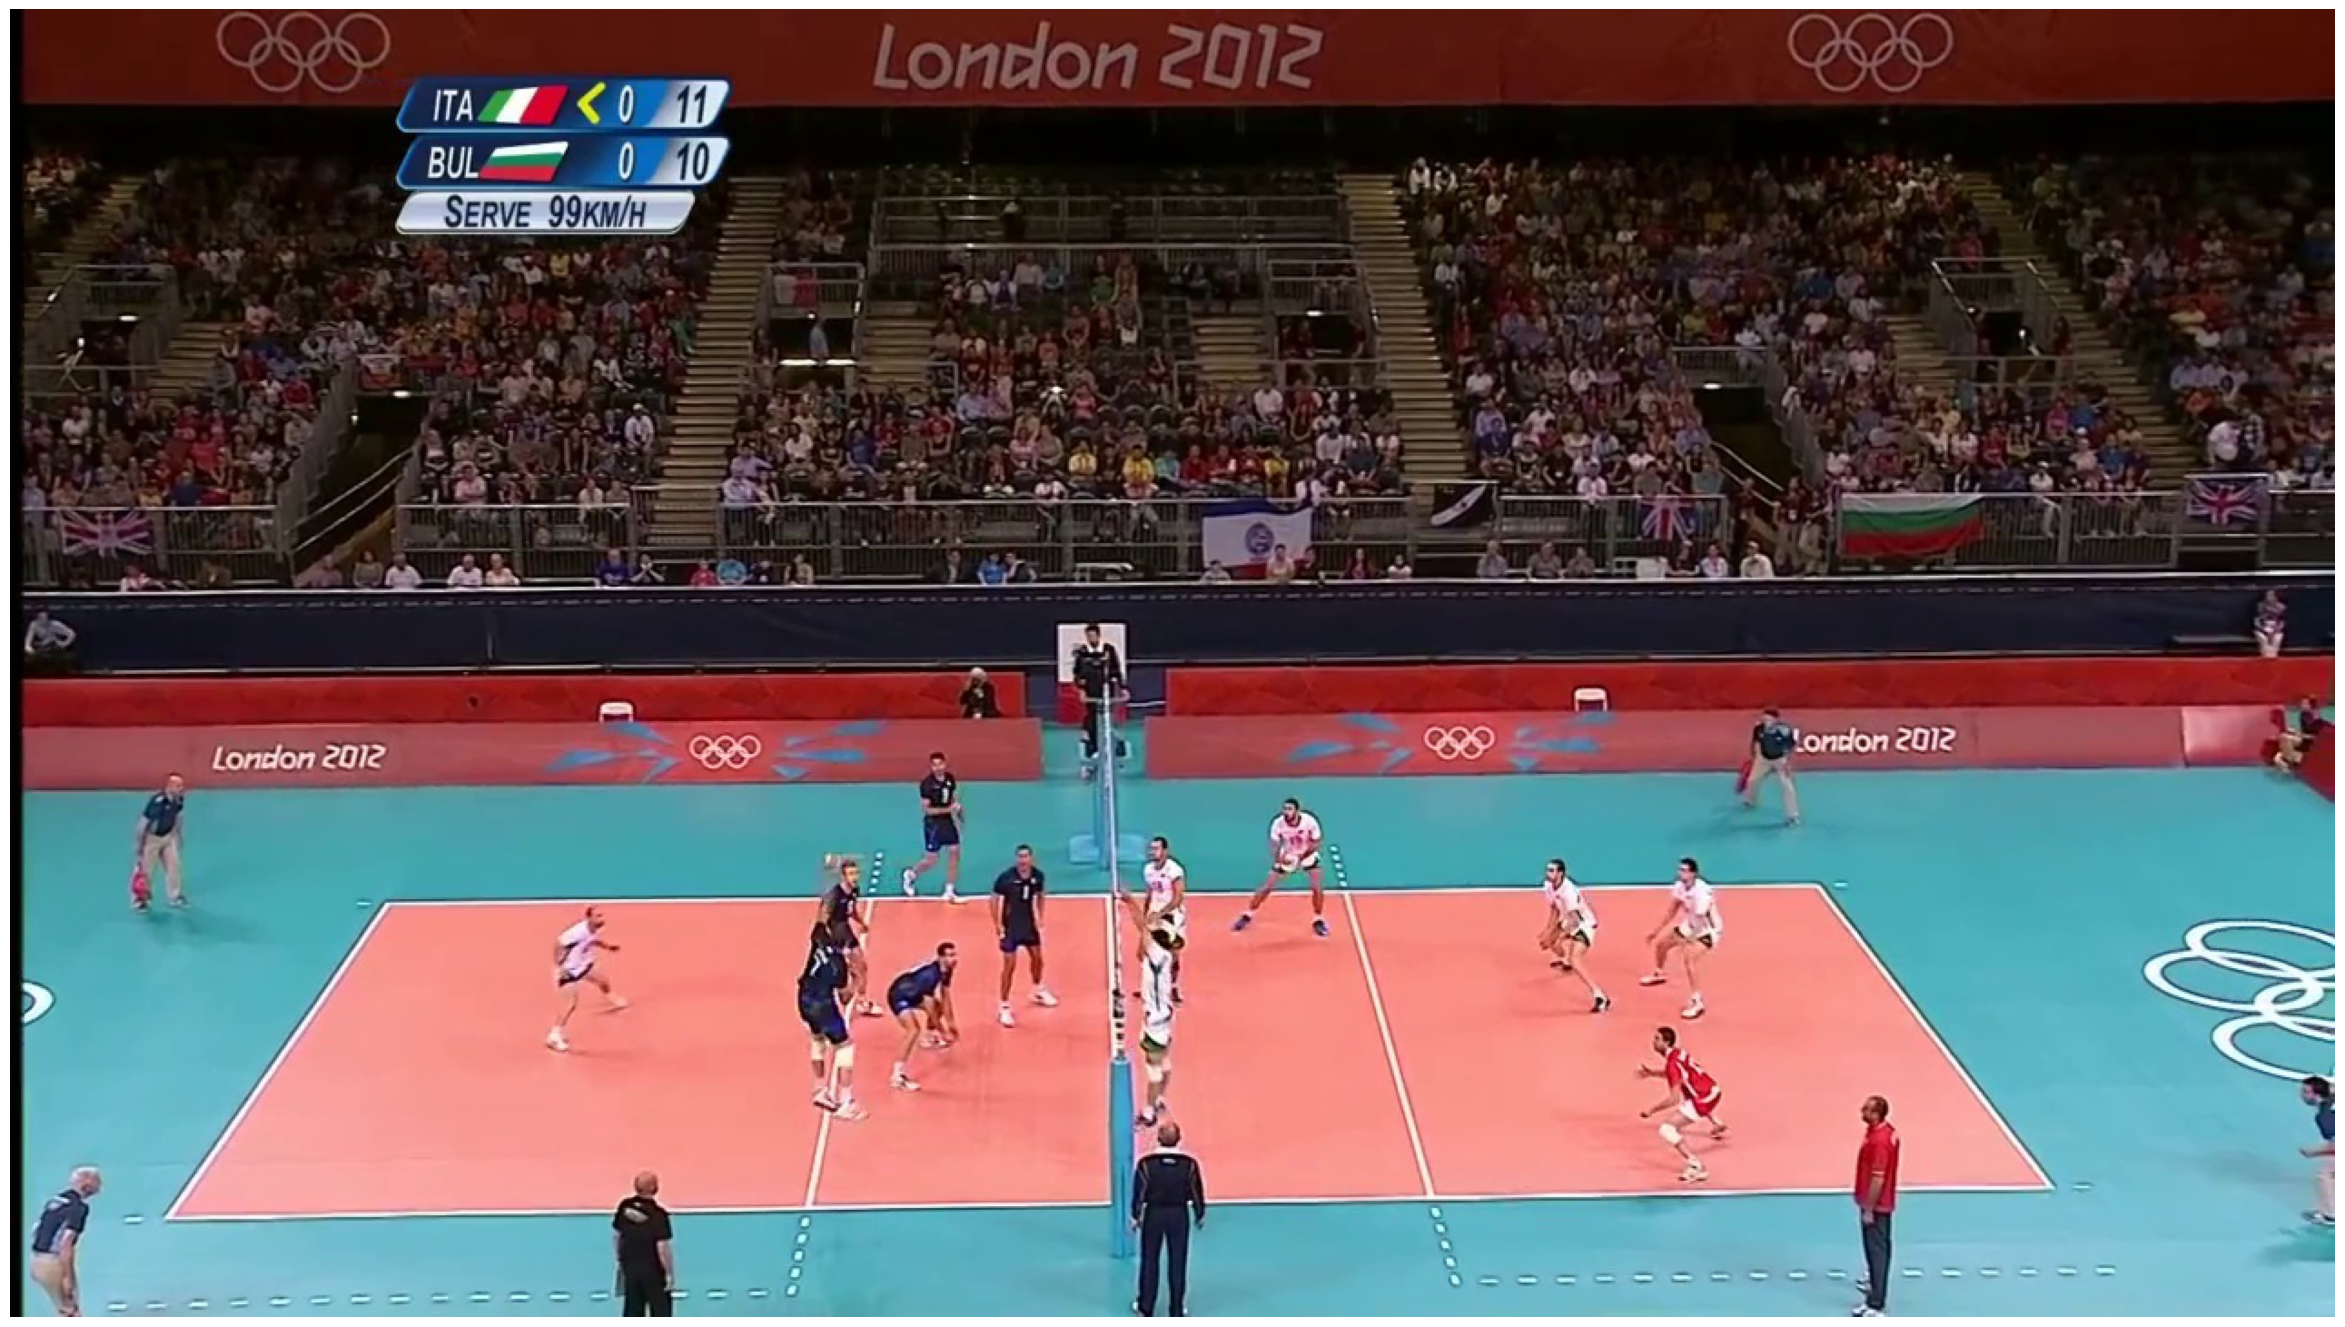

In [194]:
import matplotlib.pyplot as plt

from PIL import Image  

# 创建figure对象
fig = plt.figure(figsize=(30,40)) # 每调用一次plt.figure()函数就会创建一个新的显示窗口，与matlab中的figure类似
plt.imshow(images[5].cpu().detach().numpy().transpose(1,2,0).astype(int))
plt.axis('off')
plt.savefig('./figtest.jpg')
# im=Image.fromarray(images[1].cpu().detach().numpy().transpose(1,2,0).astype(int)) # numpy 转 image类
# im.show()
# for i in range(images.shape[0]):
#     subplot = fig.add_subplot(5, 2, i+1) # 2表示2行，3表示3列，1表示2行3列中的索引位置1
#     subplot.imshow(images[i].cpu().detach().numpy().transpose(1,2,0).astype(int))
#     subplot.axis('off')

In [195]:
gasn = torch.stack((gas[0],gas[1]),dim =1).reshape(-1,12)
gasn = gasn.cpu().detach().numpy()

In [173]:
gasn.shape

(10, 12)

In [197]:
seq[0]

array([ 0,  1,  2,  5,  3,  4,  6,  7,  8,  9, 11, 10])

In [196]:
gasn[:,seq[0]][3]

array([0.013934  , 0.8668032 , 0.04845447, 0.01113273, 0.04346833,
       0.01620714, 0.04815707, 0.63603693, 0.05768069, 0.13519257,
       0.06672415, 0.05620856], dtype=float32)

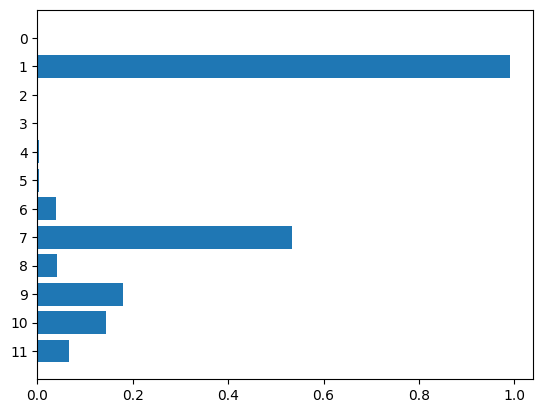

In [198]:
import matplotlib.pyplot as plt
import numpy as np

# Fixing random state for reproducibility
np.random.seed(19680801)

fig, ax = plt.subplots()

# Example data
y_pos = np.arange(12)
performance = gasn[:,seq[0]][0]

ax.barh(y_pos, performance, align='center')
ax.set_yticks(y_pos, labels=y_pos)
ax.invert_yaxis()  # labels read top-to-bottom
plt.savefig('./figimportance.jpg')
plt.show()

In [62]:
vis[0].shape

torch.Size([1, 10, 12, 12])

In [63]:
len(vis)

1

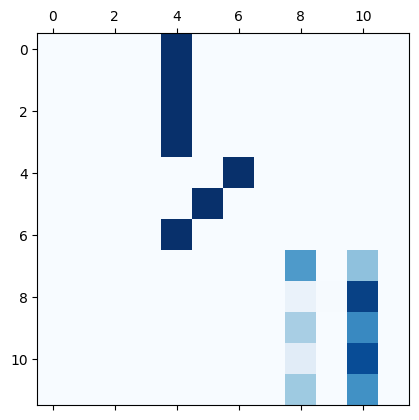

In [44]:
import matplotlib.pyplot as plt
plt.matshow(vis[0][0][3].cpu(), cmap=plt.cm.Blues)

In [99]:
visual[seq[0],:][:,seq[0]]

array([[1.00000000e+00, 5.44926267e-30, 0.00000000e+00, 6.11386520e-42,
        2.31130169e-41, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [1.00000000e+00, 1.02736093e-14, 5.75865187e-27, 5.31704569e-22,
        1.20760322e-21, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [1.00000000e+00, 5.55102879e-08, 2.92021888e-16, 2.51443172e-11,
        1.00715671e-12, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [9.99961019e-01, 3.89488268e-05, 1.76651825e-12, 9.61408908e-09,
        1.40494016e-09, 0.00000000e+00, 2.15649405e-14, 7.92942470e-19,
        2.81226323e-12, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [1.00000000e+00, 1.62576143e-13, 9.19389743e-23, 5.27626211e-18,
        2.39428235e-18, 0.00000000e+00, 0.00000000e+00, 0.00

In [54]:
visual[seq[0],:][:,seq[0]]

array([[1.04651585e-08, 8.84349571e-09, 2.20724964e-03, 1.27206638e-03,
        9.96520638e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [9.13660880e-09, 7.71121922e-09, 2.11097021e-03, 1.21165265e-03,
        9.96677399e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 4.66485927e-03, 9.95335162e-01,
        8.42709776e-36, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 3.51938745e-03, 9.96480644e-01,
        1.19124921e-37, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [4.24085045e-10, 3.63820779e-10, 1.19272005e-20, 1.11473069e-21,
        1.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00

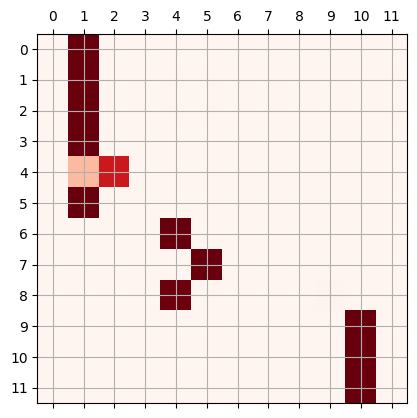

In [199]:
visual = vis[0][0][3].cpu().detach().numpy()
fig, ax = plt.subplots()
ax.matshow(visual[seq[0],:][:,seq[0]], cmap=plt.cm.Reds)
ax.set_yticks([i for i in range(12)])
ax.set_xticks([i for i in range(12)])
ax.grid(True)
plt.savefig('./figatts.jpg')

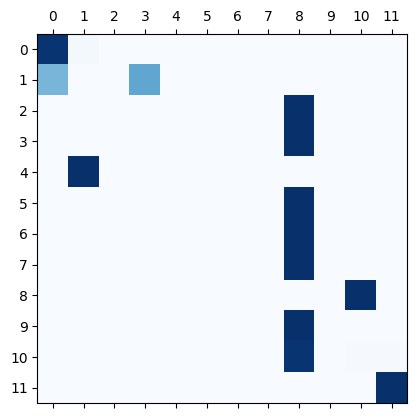

In [189]:

fig, ax = plt.subplots()
ax.matshow(visual, cmap=plt.cm.Blues)
ax.set_yticks([i for i in range(12)])
ax.set_xticks([i for i in range(12)])